In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import os

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Використовується пристрій: {device}")

data_dir = 'chest_xray'
train_dir = os.path.join(data_dir, 'train')
test_dir = os.path.join(data_dir, 'test')

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(train_dir, transform=transform)
test_dataset = datasets.ImageFolder(test_dir, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

class_names = train_dataset.classes
print(f"Класи: {class_names}")
print(f"Розмір навчальної вибірки: {len(train_dataset)}")
print(f"Розмір тестової вибірки: {len(test_dataset)}")

Використовується пристрій: cpu
Класи: ['NORMAL', 'PNEUMONIA']
Розмір навчальної вибірки: 5216
Розмір тестової вибірки: 624


In [4]:
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

for param in model.parameters():
    param.requires_grad = False

num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 2)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.0001)

epochs = 5
print("Початок навчання...")

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        
    epoch_loss = running_loss / len(train_loader)
    print(f"Епоха [{epoch+1}/{epochs}], Loss: {epoch_loss:.4f}")

print("Навчання завершено!")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Lenovo/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:04<00:00, 9.51MB/s]


Початок навчання...
Епоха [1/5], Loss: 0.4705
Епоха [2/5], Loss: 0.3077
Епоха [3/5], Loss: 0.2518
Епоха [4/5], Loss: 0.2220
Епоха [5/5], Loss: 0.2058
Навчання завершено!


Метрики якості на тестовій вибірці:
Accuracy : 0.8317
Precision: 0.7975
Recall   : 0.9795
F1-score : 0.8792


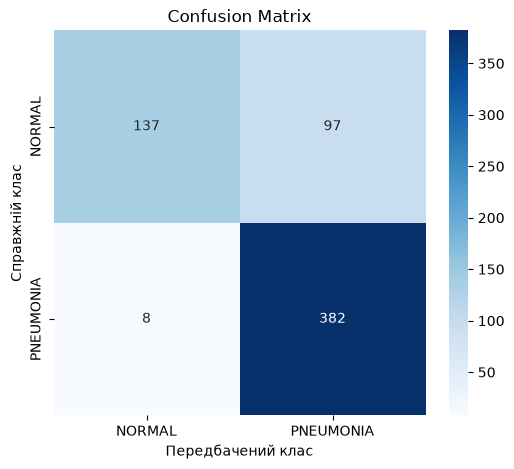

Модель успішно збережено у файл pneumonia_resnet18.pth


In [5]:
model.eval()
y_true = []
y_pred = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred)
rec = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print("Метрики якості на тестовій вибірці:")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-score : {f1:.4f}")

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Передбачений клас')
plt.ylabel('Справжній клас')
plt.title('Confusion Matrix')
plt.show()

save_path = 'pneumonia_resnet18.pth'
torch.save(model.state_dict(), save_path)
print(f"Модель успішно збережено у файл {save_path}")

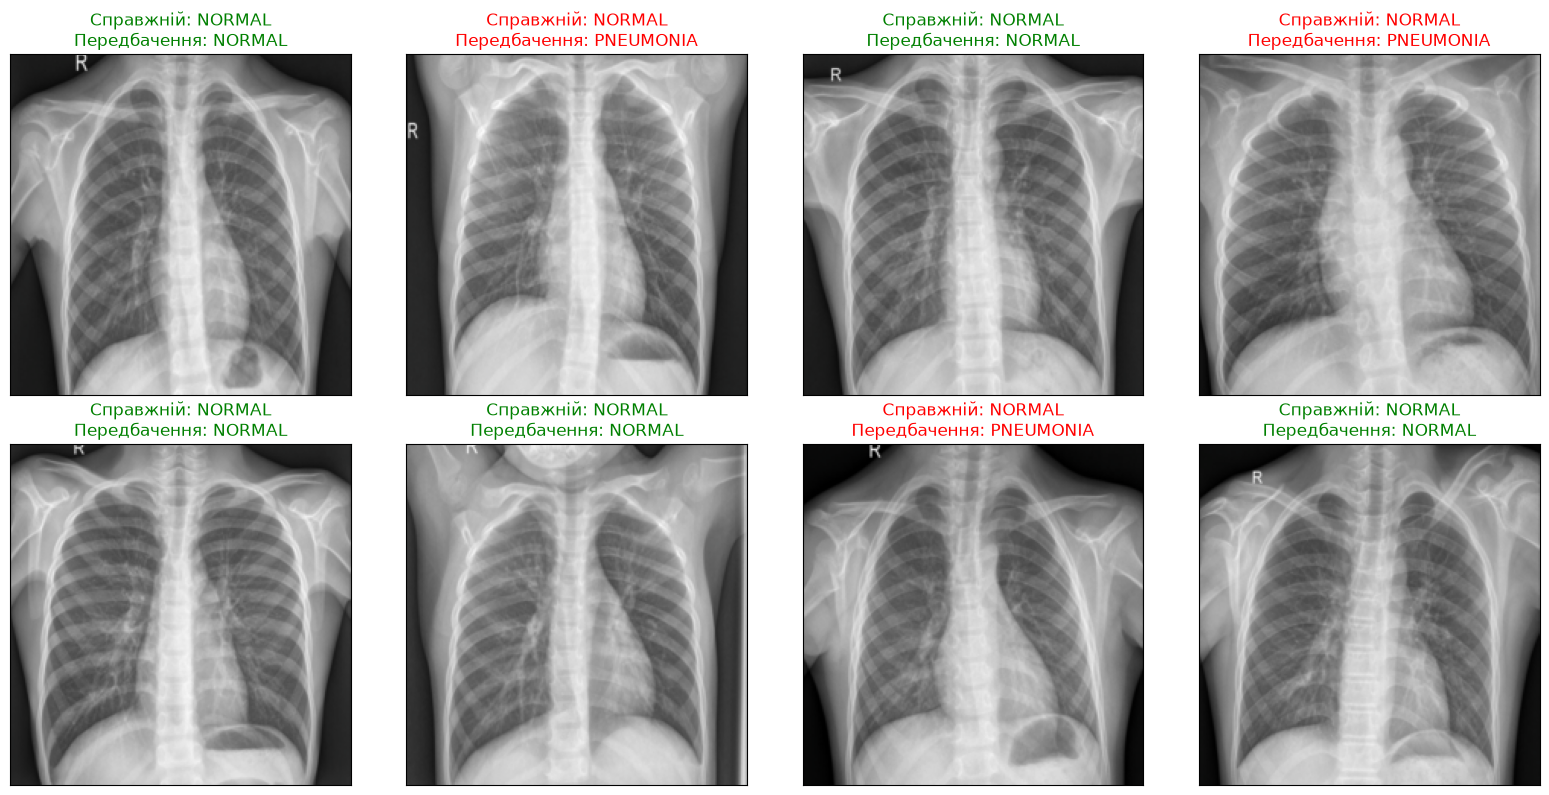

Графік збережено як pneumonia_predictions.png


In [6]:
def imshow(inp, title=None):
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    return inp

dataiter = iter(test_loader)
images, labels = next(dataiter)

images_dev = images.to(device)
outputs = model(images_dev)
_, preds = torch.max(outputs, 1)

images = images[:8]
labels = labels[:8]
preds = preds[:8]

fig = plt.figure(figsize=(16, 8))
for idx in range(8):
    ax = fig.add_subplot(2, 4, idx+1, xticks=[], yticks=[])
    img = imshow(images[idx])
    ax.imshow(img)
    
    true_label = class_names[labels[idx]]
    pred_label = class_names[preds[idx]]

    color = "green" if true_label == pred_label else "red"
    ax.set_title(f"Справжній: {true_label}\nПередбачення: {pred_label}", color=color)

plt.tight_layout()
plt.savefig('pneumonia_predictions.png')
plt.show()
print("Графік збережено як pneumonia_predictions.png")